In [1]:
# /// script
# requires-python = ">=3.14"
# dependencies = [
#     "folium",
#     "matplotlib",
#     "httpx2",
# ]
# ///

# async-titiler demo: GeoTIFF

This notebook shows how to use a locally running **async-titiler** server to:

1. read metadata from a Cloud Optimized GeoTIFF (COG),
2. compute dataset statistics to choose good visualization parameters,
3. display map tiles on an interactive map.

The first cell is an inline script metadata block ([PEP 723](https://peps.python.org/pep-0723/)) listing the notebook's dependencies, so tools like `uv` can install them automatically.

In [2]:
import json
import httpx2 as httpx
from folium import Map, TileLayer

from matplotlib import pyplot as plt

## Start the tiler server

The notebook talks to an async-titiler instance over HTTP. Before running the next cells, start the development server from the root of the `async-titiler` repository (command below). `--reload` restarts the server when the code changes, which is handy while developing.

In [3]:
# Run the local development server on your terminal

# uv run --extra server uvicorn async_titiler.main:app --port 8000 --workers 2 --reload

In [4]:
# Base URL of the tiler server started above (change it if you use another host/port)
titiler_endpoint = "http://127.0.0.1:8000"

## GeoTIFF Example

The `/geotiff` endpoints read Cloud Optimized GeoTIFFs. Every request takes the file location as a `url` query parameter.

For this example we use a single band (`B04`, red) from a Sentinel-2 L2A scene, stored as a COG in a public S3 bucket.

In [5]:
# Sentinel-2 L2A red band (B04) for tile 26SMJ, acquired 2026-08-10
geotiff_url = "https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/cogs/S2C_26SMJ_20260810_0_L2A_B04.tif"

### Metadata

`/geotiff/info` returns the dataset's basic properties without reading pixel data: bounds, CRS, data type, band count and descriptions, nodata value, available overviews, etc.

In [6]:
# Fetch file metadata (bounds, CRS, dtype, bands, overviews...)
r = httpx.get(
    f"{titiler_endpoint}/geotiff/info",
    params={
        "url": geotiff_url,
    },
).json()

# Pretty-print the JSON response
print(json.dumps(r, indent=4))

{
    "bounds": [
        399960.0,
        4290240.0,
        509760.0,
        4400040.0
    ],
    "crs": "http://www.opengis.net/def/crs/EPSG/0/32626",
    "band_metadata": [
        [
            "b1",
            {}
        ]
    ],
    "band_descriptions": [
        [
            "b1",
            "b1"
        ]
    ],
    "dtype": "uint16",
    "nodata_type": "Nodata",
    "colorinterp": [
        "GRAY"
    ],
    "scales": [
        1.0
    ],
    "offsets": [
        0.0
    ],
    "driver": "GTiff",
    "count": 1,
    "width": 10980,
    "height": 10980,
    "overviews": [
        2,
        4,
        8,
        16
    ],
    "nodata_value": 0.0
}


### Statistics

The dataset is `uint16`, but web map tiles (PNG/JPEG) are 8-bit. To get a readable image, pixel values must be **rescaled** from a chosen `min,max` range to `0-255`.

`/geotiff/statistics` computes per-band statistics (min/max, mean, median, percentiles, histogram) on a decimated version of the data (an overview), which is fast and good enough to pick rescale values.

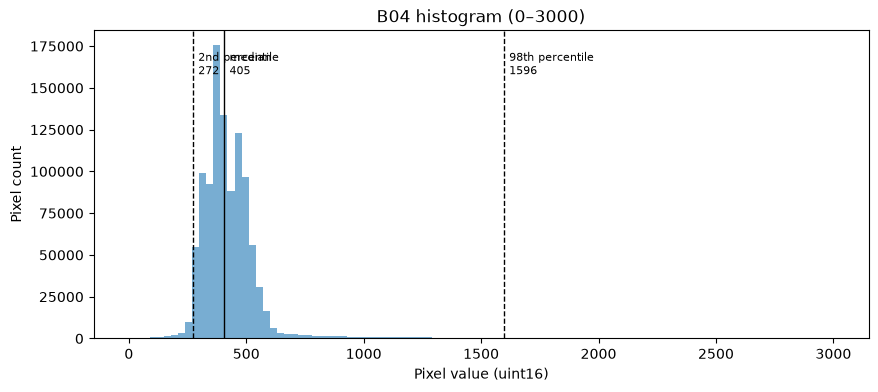

In [7]:
# Display the histogram to choose rescale values.
# The default histogram (10 bins over the full min/max range) is too coarse: almost every pixel
# lands in the first bin because of a few very bright outliers. We request a finer histogram
# focused on the range where the data actually is, using `histogram_bins` and `histogram_range`.
r = httpx.get(
    f"{titiler_endpoint}/geotiff/statistics",
    params={
        "url": geotiff_url,
        "histogram_bins": 100,
        # NOTE: Focus on the range where most of the pixel values are expected to fall (dataset knowledge)
        "histogram_range": "0,3000",
    },
).json()

stats = r["b1"]
counts, edges = stats["histogram"]  # len(edges) == len(counts) + 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(counts, edges, fill=True, alpha=0.6)

# Mark the values commonly used as rescale bounds
for value, label, style in [
    (stats["percentile_2"], "2nd percentile", "--"),
    (stats["median"], "median", "-"),
    (stats["percentile_98"], "98th percentile", "--"),
]:
    ax.axvline(value, color="k", linestyle=style, linewidth=1)
    ax.annotate(
        f"{label}\n{value:g}",
        (value, max(counts)),
        xytext=(4, -4),
        textcoords="offset points",
        va="top",
        fontsize=8,
    )

ax.set_xlabel("Pixel value (uint16)")
ax.set_ylabel("Pixel count")
ax.set_title("B04 histogram (0–3000)")
plt.show()

### Display tiles on a map

`/geotiff/{tileMatrixSetId}/tilejson.json` returns a [TileJSON](https://github.com/mapbox/tilejson-spec) document describing the tile layer: its bounds, zoom range, and a templated tile URL (`.../tiles/{z}/{x}/{y}`). Query parameters passed here (like `rescale`) are forwarded into the tile URL.

`WebMercatorQuad` is the standard web map grid (EPSG:3857) used by Leaflet/folium.

In [8]:
# Display tiles (first fetch tilejson to get the layer bounds and tiles URL)
r = httpx.get(
    f"{titiler_endpoint}/geotiff/WebMercatorQuad/tilejson.json",
    params={
        "url": geotiff_url,
        # Linearly stretch values in [272, 1596](2nd/98th percentiles) to [0, 255]; values above 1596 are clipped to white.
        "rescale": "272,1596",
    },
).json()

# Bounds are in geographic coordinates: [west, south, east, north]
bounds = r["bounds"]

# Center the map on the dataset (folium expects (lat, lon))
m = Map(
    location=((bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2), zoom_start=10
)

# Add the tiler layer using the templated tile URL from the TileJSON
TileLayer(tiles=r["tiles"][0], opacity=1, attr="Sentinel-2").add_to(m)
m